In [1]:
import os
from pathlib import Path
import SimpleITK as sitk
from tqdm.auto import tqdm
from matplotlib import pyplot as plt
from PIL import Image


/Users/igor.varha/miniconda3/envs/mouseSkullPipelines/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#

all_cohorts_folder = Path(r"/home/varhai/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp")

output_folder = Path(r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/mouse_skull_workdir/head_image_top")
output_folder.mkdir(exist_ok=True, parents=True)


In [4]:

def generate_projection_image(input_image: sitk.Image, axis=1):
    # find the first image
    projection_filter = sitk.MaximumProjectionImageFilter()
    # projection_filter = sitk.StandardDeviationProjectionImageFilter()
    # projection_filter = sitk.MedianProjectionImageFilter()
    # projection_filter = sitk.MeanProjectionImageFilter()
    # projection_filter = sitk.SumProjectionImageFilter()
    projection_filter.SetProjectionDimension(axis)
    projection_image = projection_filter.Execute(input_image)
    return projection_image



In [4]:
# iterate over all the cohorts

image_files = []
for cohort_folder in tqdm(all_cohorts_folder.iterdir()):
    if not (cohort_folder / 'skull_shape_workdir').exists():
        continue

    for subj_folder in (cohort_folder / 'skull_shape_workdir').iterdir():
        if not subj_folder.is_dir():
            continue

        # find the first image
        if (subj_folder/ 'ct_image.nii.gz').exists():
            image_files.append(subj_folder/ 'ct_image.nii.gz')





0it [00:00, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]


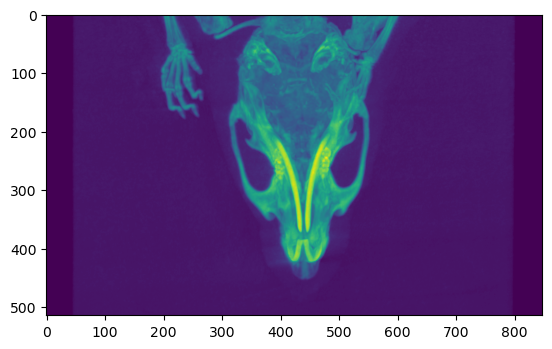

In [6]:
i =0

for image_file in tqdm(image_files):
    image = sitk.ReadImage(str(image_file))

    projection_image = generate_projection_image(image, axis=1)
    # save the image
    fig, ax = plt.subplots(1,1)
    #print(str(output_folder / (image_file.parent.name + ".png")))
    plt.imshow(sitk.GetArrayFromImage(projection_image)[:,0,:])
    break
    image = Image.fromarray(sitk.GetArrayFromImage(projection_image)[:,0,:])
    image.save(str(output_folder / (image_file.parent.name + ".png")))
    # plot the image
    
    i+=1
    if i>500:
        break
    # save the image
    #plt.savefig(str(output_folder / (image_file.parent.name + ".png")))
    #break

In [9]:
sitk.GetArrayFromImage(projection_image)[:,0,:]

array([[ 0,  0,  0, ..., 12, 12, 11],
       [ 0,  0,  0, ..., 11, 11, 10],
       [ 0,  0,  0, ..., 11, 11, 10],
       ...,
       [ 0,  0,  0, ...,  8,  8,  9],
       [ 0,  0,  0, ...,  8,  8,  9],
       [ 0,  0,  0, ..., 10,  9,  8]], dtype=uint8)

In [5]:
plt.imshow(sitk.GetArrayFromImage(projection_image)[:,0,:])


NameError: name 'projection_image' is not defined

In [7]:
len(image_files)

6390

In [2]:
image_files = ['/Users/igor.varha/CCP_workdir/ref_mouse/oriented_image.nii.gz']

In [7]:
image = Image.fromarray(sitk.GetArrayFromImage(projection_image)[:,0,:])


In [9]:
image.save('/Users/igor.varha/CCP_workdir/ref_mouse/oriented_image_top.png')